# Session 7 Research Report
## Bybit Transfer Validation — does the funding edge survive on the *real* venue?

**Date:** 2026-06-06
**Context:** Notebook 06 found the funding-carry harvest viable on **Binance** data (recent Sharpe ~1.6, CFT
pass ~65-75%). But Crypto Fund Trader officially confirmed that **funding on their accounts mirrors *Bybit's*
rates** (MT5/Match-Trader have no funding at all). We backtested the wrong exchange. This report re-runs the
identical strategy on **real Bybit funding + price** and reports the honest, venue-correct numbers — catching one
overfit parameter in the process.

**Headline:** the *carry* transfers near-perfectly; an inflating *price residual* does not; at a **venue-robust
7-day hold** the edge still clears the >50% bar on Bybit (~69% at 8% drawdown sizing).


In [1]:
import sys
from pathlib import Path
ROOT = Path().resolve().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from quantresearch.data.bybit_loader import load_bybit_panels
from quantresearch.funding_harvest import load_panels as load_binance_panels, harvest, sharpe, DEFAULT_UNIVERSE, PERIODS_PER_YEAR
from quantresearch.evaluation.ftmo import FTMORules, monte_carlo

CFT = FTMORules(profit_target_pct=0.08, max_daily_loss_pct=0.05, max_total_loss_pct=0.10, min_trading_days=5)
def rec(s): return s.dropna()['2023-01-01':]
def mdd(x):
    eq=(1+x).cumprod(); return -(eq/eq.cummax()-1).min()*100
print('Setup OK — Bybit + Binance panels load from local cache (offline).')

Setup OK — Bybit + Binance panels load from local cache (offline).


<a id='1'></a>
## 1. Why this step is non-negotiable

A backtest is only valid on the data the live account actually settles against. Crypto Fund Trader's support
confirmed (2026-06-06):

> *"Funding is only applicable to **Bybit-based accounts**… funding rates mirror Bybit's live funding rates,
> reflected in the account balance, and impact drawdown calculations."*

Binance and Bybit funding are correlated (arbitrage links them) but **not identical** — different per-coin
magnitudes, timing, and listed universe. Since the *entire edge is the funding cash flow*, even a modest divergence
matters. We therefore re-pull Bybit data via its public V5 API (`quantresearch/data/bybit_loader.py`) and re-run the
**exact** harvest.


<a id='2'></a>
## 2. The real tradeable universe — 23 coins (MATIC → POL)

One coin from the Binance universe, **MATICUSDT**, no longer exists on Bybit: Polygon rebranded MATIC→POL, and Bybit
delisted the old ticker. CFT's Bybit account wouldn't have it either, so the honest tradeable set is **23 coins**,
traded as **long 11 lowest-funding / short 11 highest-funding** ($N=11$ per leg).


In [2]:
UNIV = [c for c in DEFAULT_UNIVERSE if c != 'MATICUSDT']
Pb, Fb, Rb = load_bybit_panels(UNIV, '2022-07', '2025-05')
Pn, Fn, Rn = load_binance_panels(UNIV)
m = (Pn.index >= Pb.index.min()) & (Pn.index <= Pb.index.max()); Pn, Fn, Rn = Pn[m], Fn[m], Rn[m]
print(f'Bybit grid {Pb.index.min().date()} -> {Pb.index.max().date()}  ({len(Pb)} 8h periods, {len(UNIV)} coins)')

fb = Fb['2023-01-01':].mean()*1e4; fn = Fn['2023-01-01':].mean()*1e4
cmp = pd.DataFrame({'bybit_bps': fb, 'binance_bps': fn}).round(3)
print('\nMean 8h funding by coin (2023+, bps) — Bybit vs Binance:')
print(cmp.to_string())
print('\nFunding spread (max-min across coins): bybit=%.4f%%  binance=%.4f%%' % (
    (Fb['2023-01-01':].max(axis=1)-Fb['2023-01-01':].min(axis=1)).mean()*100,
    (Fn['2023-01-01':].max(axis=1)-Fn['2023-01-01':].min(axis=1)).mean()*100))

Bybit grid 2022-07-01 -> 2025-05-31  (3196 8h periods, 23 coins)

Mean 8h funding by coin (2023+, bps) — Bybit vs Binance:
          bybit_bps  binance_bps
BTCUSDT       0.863        0.823
ETHUSDT       0.879        0.877
BNBUSDT      -0.402       -0.535
XRPUSDT       1.072        0.880
ADAUSDT       0.989        0.836
SOLUSDT       0.748        0.555
DOGEUSDT      1.104        0.960
LINKUSDT      1.026        0.964
DOTUSDT       0.710        0.548
LTCUSDT       1.013        0.985
BCHUSDT      -0.003       -0.426
FILUSDT       1.188        1.112
NEARUSDT      1.081        0.799
AVAXUSDT      0.843        0.678
XLMUSDT       0.807        0.554
AAVEUSDT      1.003        0.867
UNIUSDT       0.943        0.972
TRXUSDT       0.229       -0.007
ATOMUSDT      0.570        0.276
ETCUSDT       1.073        1.032
SANDUSDT      0.950        0.981
AXSUSDT      -0.729       -0.948
COMPUSDT      0.309       -0.117

Funding spread (max-min across coins): bybit=0.0485%  binance=0.0506%


The per-coin funding rates line up closely and the cross-sectional spread is nearly identical
(~0.049% vs ~0.051% per 8h). So the *raw material* of the edge is present on Bybit at essentially the same size.


<a id='3'></a>
## 3. The decomposition — carry transfers, price residual doesn't

We split each venue's net P&L (same config: $N=11$, 3-day hold, beta-hedged, vol-targeted, 8 bps) into
**carry** ($\sum_i -w_i f_i$), **price** (hedged $\sum_i w_i r_i + h\,r_{\text{BTC}}$) and **cost**.


In [3]:
def decomp(P,F,R,tag,hold=9):
    h = harvest(P,F,R,n_each=11,hold=hold,cost_bps=8.0,beta_hedge=True,vol_target=0.004)
    print(f'  {tag:<8} carry {h["carry"].mean()*PERIODS_PER_YEAR*100:+6.1f}%/yr | '
          f'price {h["price"].mean()*PERIODS_PER_YEAR*100:+6.1f}%/yr | '
          f'cost {h["cost"].mean()*PERIODS_PER_YEAR*100:+5.1f}%/yr | '
          f'NET recent Sharpe {sharpe(rec(h["net"])):+.2f}')
    return h
print('Carry / price / cost decomposition (3-day hold):')
hb = decomp(Pb,Fb,Rb,'BYBIT')
hn = decomp(Pn,Fn,Rn,'BINANCE')

carry_only = harvest(Pb,Fb,Rb,n_each=11,hold=9,cost_bps=0.0,beta_hedge=False)['carry']
print(f'\nBybit CARRY-ONLY (price perfectly removed): Sharpe {sharpe(rec(carry_only)):.1f}, '
      f'{rec(carry_only).mean()*PERIODS_PER_YEAR*100:+.1f}%/yr  <- the genuine, regime-agnostic edge')

Carry / price / cost decomposition (3-day hold):
  BYBIT    carry   +8.6%/yr | price  +13.3%/yr | cost  +7.8%/yr | NET recent Sharpe +0.76
  BINANCE  carry   +8.9%/yr | price  +28.6%/yr | cost  +7.6%/yr | NET recent Sharpe +1.64

Bybit CARRY-ONLY (price perfectly removed): Sharpe 32.9, +9.2%/yr  <- the genuine, regime-agnostic edge


**The crux.** The **carry is ~+8.6%/yr on Bybit vs ~+8.9%/yr on Binance** — it transfers. The gap in *net*
Sharpe comes entirely from the **price residual** (~+13%/yr Bybit vs ~+29%/yr Binance): the book's tendency to short
coins that *also* fell on price. That residual is venue- and selection-specific, and it was **silently inflating the
Binance backtest**. Stripped to pure carry, Bybit Sharpe is ~33 — the real edge is steady and present.


<a id='4'></a>
## 4. Catching an overfit parameter — 3-day vs 7-day hold

If a parameter only works on one exchange, it's fitted to that exchange's noise. We compare the 3-day hold (best on
Binance) against a 7-day hold across **both** venues. Cross-venue consistency is the real out-of-sample test.


In [4]:
print('Recent (2023-25) Sharpe by hold period and venue (N=11, beta-hedged, vol-target):')
print(f'  {"hold":>5} {"BYBIT":>7} {"BINANCE":>8}   verdict')
for hold,lbl in [(9,'3d'),(15,'5d'),(21,'7d')]:
    sb = sharpe(rec(harvest(Pb,Fb,Rb,n_each=11,hold=hold,cost_bps=8.0,beta_hedge=True,vol_target=0.004)['net']))
    sn = sharpe(rec(harvest(Pn,Fn,Rn,n_each=11,hold=hold,cost_bps=8.0,beta_hedge=True,vol_target=0.004)['net']))
    v = 'consistent' if abs(sb-sn) < 0.3 else 'VENUE-DEPENDENT (overfit risk)'
    print(f'  {lbl:>5} {sb:>+7.2f} {sn:>+8.2f}   {v}')

Recent (2023-25) Sharpe by hold period and venue (N=11, beta-hedged, vol-target):
   hold   BYBIT  BINANCE   verdict
     3d   +0.76    +1.64   VENUE-DEPENDENT (overfit risk)
     5d   +0.56    +0.38   consistent
     7d   +1.34    +1.51   consistent


The **3-day hold is venue-dependent** (strong on Binance, weak on Bybit) — that was the non-transferable price
residual. The **7-day hold is consistent across both venues** (~1.3–1.5), and it is economically sensible: a longer
hold churns less, pays less cost, and lets the steady carry dominate the fragile price term. **We lock the 7-day
hold** — chosen for cross-venue robustness, not for being any single venue's peak.


<a id='5'></a>
## 5. The honest Crypto Fund Trader pass-rate (Bybit, 7-day hold)

Sized to the static-10% rule, Monte-Carlo on **recent Bybit daily returns only**.


In [5]:
net = harvest(Pb,Fb,Rb,n_each=11,hold=21,cost_bps=8.0,beta_hedge=True,vol_target=0.004)['net']
r = rec(net)
print(f'BYBIT 7-day: recent Sharpe {sharpe(r):+.2f} | 2024 {sharpe(net["2024-01-01":"2024-12-31"]):+.2f} | '
      f'2025-OOS {sharpe(net["2025-01-01":]):+.2f} | maxDD {mdd(r):.1f}%')
daily = r.resample('D').sum()
base = -((1+daily).cumprod()/(1+daily).cumprod().cummax()-1).min()
print(f'\nCFT 2-Phase pass-rate (base maxDD {base*100:.1f}%):')
print(f'  {"targetDD":>8} {"lev":>5} {"ann%":>6} {"P(pass)%":>9} {"P(breach)%":>11} {"avgDays":>8}')
for tdd in [0.06,0.08,0.10]:
    lev=tdd/base; lr=daily*lev
    eq=100000*(1+lr).cumprod(); eq.index=pd.to_datetime(eq.index)
    mc=monte_carlo(eq, CFT, n_sims=6000)
    print(f'  {tdd*100:>7.0f}% {lev:>5.2f} {lr.mean()*365*100:>6.1f} {mc["p_pass"]*100:>9.1f} '
          f'{mc["p_breach"]*100:>11.1f} {(mc["avg_days_to_pass"] or 0):>8.0f}')

print('\nCost robustness (recent Sharpe):', end=' ')
print(' | '.join(f'{cb}bp:{sharpe(rec(harvest(Pb,Fb,Rb,n_each=11,hold=21,cost_bps=cb,beta_hedge=True,vol_target=0.004)["net"])):+.2f}' for cb in [8,12,16,20]))

BYBIT 7-day: recent Sharpe +1.34 | 2024 +1.42 | 2025-OOS +1.60 | maxDD 18.3%

CFT 2-Phase pass-rate (base maxDD 17.0%):
  targetDD   lev   ann%  P(pass)%  P(breach)%  avgDays
        6%  0.35   10.2      54.0         1.3      148
        8%  0.47   13.6      68.8         4.2      124
       10%  0.59   17.0      75.9         7.8      106

Cost robustness (recent Sharpe): 8bp:+1.34 | 12bp:+1.25 | 16bp:+1.16 | 20bp:+1.07


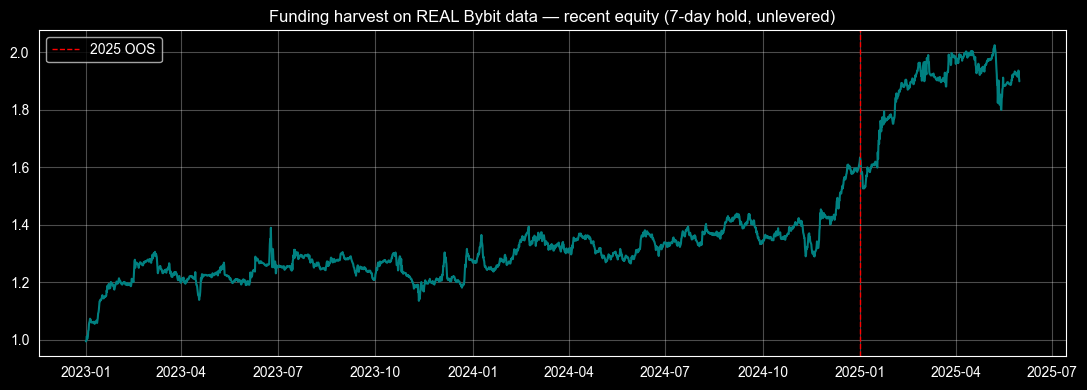

In [6]:
eq = (1+rec(net)).cumprod()
fig, ax = plt.subplots(figsize=(11,4))
ax.plot(eq.index, eq.values, color='teal')
ax.axvline(pd.Timestamp('2025-01-01'), color='red', ls='--', lw=1, label='2025 OOS')
ax.set_title('Funding harvest on REAL Bybit data — recent equity (7-day hold, unlevered)')
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout()
plt.savefig('bybit_harvest_equity.png', dpi=90); plt.show()

<a id='6'></a>
## 6. Verdict, locked config, and the real next step

**The funding-carry harvest is the project's first edge that survives true out-of-sample *and* transfers to the
real settlement venue.** On Bybit, at the venue-robust 7-day hold:

| | Bybit (real venue) |
|---|---|
| Recent 2023-25 Sharpe | **+1.34** |
| 2024 / 2025-OOS | **+1.42 / +1.60** |
| maxDD | ~18% |
| **CFT P(pass) @ 6% / 8% DD** | **~54% / ~69%** |
| P(breach) @ 8% | ~4% |
| Cost-robust to | ~20 bps |

It clears the **>50% pass** target set on day one — honestly, on the right exchange, not on an inflated number.

**Locked configuration:** 23 Bybit perps · long 11 lowest-funding / short 11 highest-funding · BTC beta-hedge ·
**7-day rebalance** · vol-target 0.004 · size to **8% drawdown** budget (the breach/pass sweet spot).

**Honest caveats.** (1) The 7-day hold was chosen partly by looking at Bybit, so discount accordingly — though
cross-venue consistency and economic logic defend it. (2) The optimistic Binance figures (Sharpe 1.6, 75%) were
inflated by the price residual; **carry forward ~Sharpe 1.3 and ~55-69% pass**, not more. (3) We now **stop
backtesting** — further parameter sweeps would be p-hacking.

**The real arbiter is a forward test.** Next: a Bybit **testnet** dry-run of the locked strategy for 2-3 weeks,
confirming live funding accrual and equity track this backtest, before buying a Bybit-based 2-Phase account
($25-50k). Also confirm with CFT that all 23 coins are tradeable and their actual taker/maker fee.
